In [5]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import math
import scipy.stats as stats
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report
import datetime
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression

#Load data
teams = pd.read_csv('data/clean_teams.csv')

teams

FileNotFoundError: [Errno 2] No such file or directory: 'data/clean_teams.csv'

In [ ]:
teams['playoff'] = (teams['playoff'] == 'Y').astype(int)

teams['firstRound'] = teams['firstRound'].fillna(0)
teams['firstRound'] = teams['firstRound'].replace('W',1)
teams['firstRound'] = teams['firstRound'].replace('L',1)

teams['semis'] = teams['semis'].fillna(0)
teams['semis'] = teams['semis'].replace('W',1)
teams['semis'] = teams['semis'].replace('L',1)

teams['finals'] = teams['finals'].fillna(0)
teams['finals'] = teams['finals'].replace('W',2)
teams['finals'] = teams['finals'].replace('L',1)

teams['playoff_result'] = teams['firstRound'] + teams['semis'] + teams['finals']

teams = teams.drop(['firstRound','semis','finals'], axis=1)

teams['east'] = (teams['confID'] == 'EA').astype(int)
teams['west'] = (teams['confID'] == 'WE').astype(int)

teams.drop('confID', axis=1, inplace=True)

teams

,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,homeW,homeL,awayW,awayL,confW,confL,min,playoff_result,east,west
0,0,9,ATL,0,895,2258,542,725,202,598,...,1,16,3,14,2,18,6825,0,1,0
1,1,10,ATL,1,1089,2428,569,755,114,374,...,12,5,6,11,10,12,6950,1,1,0
2,2,1,CHA,0,812,1903,431,577,131,386,...,5,11,3,13,5,16,6475,0,1,0
3,3,2,CHA,1,746,1780,410,528,153,428,...,11,5,7,9,15,6,6500,3,1,0
4,4,3,CHA,1,770,1790,490,663,211,527,...,11,5,7,9,12,9,6450,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,0,847,1968,388,546,181,510,...,10,7,6,11,9,11,6900,0,1,0
138,138,7,WAS,1,1016,2199,528,715,187,522,...,13,4,5,12,12,8,6850,1,1,0
139,139,8,WAS,0,877,2170,668,839,163,528,...,8,9,8,9,8,12,6900,0,1,0
140,140,9,WAS,0,885,2131,435,659,163,460,...,6,11,4,13,6,14,6825,0,1,0


In [ ]:
teams['win_ratio'] = teams['won'] / teams['GP']
teams['win_ratio'] = teams['win_ratio'].apply(lambda x: round(x, 2))

teams.drop(['won','lost', 'GP'], axis=1, inplace=True)

teams

,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,homeL,awayW,awayL,confW,confL,min,playoff_result,east,west,win_ratio
0,0,9,ATL,0,895,2258,542,725,202,598,...,16,3,14,2,18,6825,0,1,0,0.12
1,1,10,ATL,1,1089,2428,569,755,114,374,...,5,6,11,10,12,6950,1,1,0,0.53
2,2,1,CHA,0,812,1903,431,577,131,386,...,11,3,13,5,16,6475,0,1,0,0.25
3,3,2,CHA,1,746,1780,410,528,153,428,...,5,7,9,15,6,6500,3,1,0,0.56
4,4,3,CHA,1,770,1790,490,663,211,527,...,5,7,9,12,9,6450,1,1,0,0.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,0,847,1968,388,546,181,510,...,7,6,11,9,11,6900,0,1,0,0.47
138,138,7,WAS,1,1016,2199,528,715,187,522,...,4,5,12,12,8,6850,1,1,0,0.53
139,139,8,WAS,0,877,2170,668,839,163,528,...,9,8,9,8,12,6900,0,1,0,0.47
140,140,9,WAS,0,885,2131,435,659,163,460,...,11,4,13,6,14,6825,0,1,0,0.29


In [ ]:
#Possessions = Team Possessions = 0.5 * ((Team FGA + 0.4 * Team FTA - 1.07 * (Team OREB / (Team OREB + Opponent DREB)) * (Team FGA - Team FG) + Team TO) + (Opponent FGA + 0.4 * Opponent FTA - 1.07 * (Opponent OREB / (Opponent OREB + Team DREB)) * (Opponent FGA - Opponent FG) + Opponent TO))
teams['possesions'] = 0.5 * (teams['o_fga'] + 0.4 * teams['o_fta'] - 1.07 * (teams['o_oreb'] / (teams['o_oreb'] + teams['d_dreb'])) * (teams['o_fga'] - teams['o_fgm']) + teams['o_to']+
                             teams['d_fga'] + 0.4 * teams['d_fta'] - 1.07 * (teams['d_oreb'] / (teams['d_oreb'] + teams['o_dreb'])) * (teams['d_fga'] - teams['d_fgm']) + teams['d_to'])

In [ ]:
#OFF EFF = 100 x (Points / Possessions)
teams['off_rtg'] = 100 * (teams['o_pts'] / teams['possesions'])
teams['off_rtg'] = teams['off_rtg'].apply(lambda x: round(x, 1))

#DEF EFF = 100 x (Opponent Points / Opponent Possessions)
teams['def_rtg'] = 100 * (teams['d_pts'] / teams['possesions'])
teams['def_rtg'] = teams['def_rtg'].apply(lambda x: round(x, 1))

# NET EFF = OFF EFF - DEF EFF
teams['net_rtg'] = teams['off_rtg'] - teams['def_rtg']
teams['net_rtg'] = teams['net_rtg'].apply(lambda x: round(x, 1))

teams.drop(['possesions', 'off_rtg', 'def_rtg'], axis=1, inplace=True)
teams.head()

,Unnamed: 0,year,tmID,playoff,o_fgm,o_fga,o_ftm,o_fta,o_3pm,o_3pa,...,awayW,awayL,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg
0,0,9,ATL,0,895,2258,542,725,202,598,...,3,14,2,18,6825,0,1,0,0.12,-12.7
1,1,10,ATL,1,1089,2428,569,755,114,374,...,6,11,10,12,6950,1,1,0,0.53,2.3
2,2,1,CHA,0,812,1903,431,577,131,386,...,3,13,5,16,6475,0,1,0,0.25,-10.7
3,3,2,CHA,1,746,1780,410,528,153,428,...,7,9,15,6,6500,3,1,0,0.56,2.2
4,4,3,CHA,1,770,1790,490,663,211,527,...,7,9,12,9,6450,1,1,0,0.56,5.1


In [ ]:
teams.drop(["o_fgm", "o_fga", "o_ftm", "o_fta", "o_3pm", "o_3pa", "o_oreb", "o_dreb", "o_reb", "o_asts", "o_pf", "o_stl", "o_to", "o_blk", "o_pts"], axis=1, inplace=True)
teams.drop(["d_fgm", "d_fga", "d_ftm", "d_fta", "d_3pm", "d_3pa", "d_oreb", "d_dreb", "d_reb", "d_asts", "d_pf", "d_stl", "d_to", "d_blk", "d_pts", "homeW", "homeL", "awayW", "awayL"], axis=1, inplace=True)
teams.head()

,Unnamed: 0,year,tmID,playoff,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg
0,0,9,ATL,0,2,18,6825,0,1,0,0.12,-12.7
1,1,10,ATL,1,10,12,6950,1,1,0,0.53,2.3
2,2,1,CHA,0,5,16,6475,0,1,0,0.25,-10.7
3,3,2,CHA,1,15,6,6500,3,1,0,0.56,2.2
4,4,3,CHA,1,12,9,6450,1,1,0,0.56,5.1


In [ ]:
players_teams_data = pd.read_csv("data/players_teams.csv")

In [ ]:
# delete players who haven't played
players_teams_data = players_teams_data[players_teams_data['minutes'] != 0]

#players_teams_data['UE'] = (players_teams_data['fgAttempted'] + 0.44 * players_teams_data['ftAttempted'] + players_teams_data['turnovers']) * 100 / players_teams_data['minutes']
players_teams_data['PPG'] = players_teams_data['points'] / players_teams_data['GP']
players_teams_data['SPG'] = players_teams_data['steals'] / players_teams_data['GP']
players_teams_data['TOVPG'] = players_teams_data['turnovers'] / players_teams_data['GP']



#players_teams_data['x'] = players_teams_data['points'] / (players_teams_data['fgAttempted'] + players_teams_data['fgAttempted'] + players_teams_data['turnovers'] - players_teams_data['oRebounds'])
#players_teams_data['x'] = players_teams_data['points'] / 2* (players_teams_data['fgAttempted'] + 0.44 * players_teams_data['ftAttempted'])
#players_teams_data['x'] = players_teams_data['rebounds'] / players_teams_data['GP']
#players_teams_data['x'] = players_teams_data['fgMade'] / players_teams_data['fgAttempted']
#players_teams_data['x'] = players_teams_data['assists'] / players_teams_data['GP']
#players_teams_data['x'] = players_teams_data['blocks'] / players_teams_data['GP']

#players_teams_data['PPP'] = players_teams_data['points'] / (players_teams_data['fgAttempted'] + players_teams_data['fgAttempted'] + players_teams_data['turnovers'] - players_teams_data['oRebounds'])
#players_teams_data['TSP'] = players_teams_data['points'] / 2* (players_teams_data['fgAttempted'] + 0.44 * players_teams_data['ftAttempted'])
# players_teams_data['RPG'] = players_teams_data['rebounds'] / players_teams_data['GP']
#players_teams_data['FER'] = players_teams_data['fgMade'] / players_teams_data['fgAttempted']
#players_teams_data['APG'] = players_teams_data['assists'] / players_teams_data['GP']
#players_teams_data['BPG'] = players_teams_data['blocks'] / players_teams_data['GP']

In [ ]:
players_teams_data['PPG'] = players_teams_data['PPG'].apply(lambda x: round(x, 1))

players_teams_data['SPG'] = players_teams_data['SPG'].apply(lambda x: round(x, 1))

players_teams_data['TOVPG'] = players_teams_data['TOVPG'].apply(lambda x: round(x, 1))

players_teams_data[['playerID', 'year', 'PPG', 'SPG', 'TOVPG']]

,playerID,year,PPG,SPG,TOVPG
0,abrossv01w,2,13.2,1.6,3.3
1,abrossv01w,3,11.6,1.6,3.4
2,abrossv01w,4,10.6,1.5,3.0
3,abrossv01w,5,6.6,1.4,2.0
4,abrossv01w,6,9.8,1.5,2.6
...,...,...,...,...,...
1871,zakalok01w,3,1.2,0.0,0.8
1872,zarafr01w,6,2.6,0.5,1.2
1873,zellosh01w,10,11.9,0.8,2.3
1874,zirkozu01w,4,1.8,0.0,0.3


In [ ]:
players_teams_data.drop(["points", "steals", 'turnovers', "GP"], axis=1, inplace=True)
players_teams_data

,playerID,year,stint,tmID,lgID,GS,minutes,oRebounds,dRebounds,rebounds,...,PostfgAttempted,PostfgMade,PostftAttempted,PostftMade,PostthreeAttempted,PostthreeMade,PostDQ,PPG,SPG,TOVPG
0,abrossv01w,2,0,MIN,WNBA,23,846,43,131,174,...,0,0,0,0,0,0,0,13.2,1.6,3.3
1,abrossv01w,3,0,MIN,WNBA,27,805,45,101,146,...,0,0,0,0,0,0,0,11.6,1.6,3.4
2,abrossv01w,4,0,MIN,WNBA,25,792,44,97,141,...,22,6,8,8,7,3,0,10.6,1.5,3.0
3,abrossv01w,5,0,MIN,WNBA,11,462,17,57,74,...,23,8,4,2,8,2,0,6.6,1.4,2.0
4,abrossv01w,6,0,MIN,WNBA,31,777,29,78,107,...,0,0,0,0,0,0,0,9.8,1.5,2.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1871,zakalok01w,3,2,PHO,WNBA,0,37,0,3,3,...,0,0,0,0,0,0,0,1.2,0.0,0.8
1872,zarafr01w,6,0,SEA,WNBA,4,413,11,28,39,...,6,4,2,2,1,1,0,2.6,0.5,1.2
1873,zellosh01w,10,0,DET,WNBA,4,802,25,81,106,...,68,24,27,23,17,7,0,11.9,0.8,2.3
1874,zirkozu01w,4,0,WAS,WNBA,0,30,0,2,2,...,0,0,0,0,0,0,0,1.8,0.0,0.3


In [ ]:
average_ppg = players_teams_data.groupby(['year', 'tmID'])['PPG'].mean().reset_index()
average_ppg['PPG'] = average_ppg['PPG'].apply(lambda x: round(x, 2))
average_ppg

average_spg = players_teams_data.groupby(['year', 'tmID'])['SPG'].mean().reset_index()
average_spg['SPG'] = average_spg['SPG'].apply(lambda x: round(x, 2))
average_spg

average_tovpg= players_teams_data.groupby(['year', 'tmID'])['TOVPG'].mean().reset_index()
average_tovpg['TOVPG'] = average_tovpg['TOVPG'].apply(lambda x: round(x, 2))
average_tovpg

,year,tmID,TOVPG
0,1,CHA,1.42
1,1,CLE,1.53
2,1,DET,1.40
3,1,HOU,1.22
4,1,IND,1.30
...,...,...,...
137,10,PHO,1.43
138,10,SAC,1.38
139,10,SAS,1.58
140,10,SEA,1.49


In [ ]:
teams = pd.merge(teams, average_ppg, how='left', left_on=['year', 'tmID'], right_on=['year', 'tmID'], suffixes=('', '_avg_ppg'))
teams = pd.merge(teams, average_spg, how='left', left_on=['year', 'tmID'], right_on=['year', 'tmID'], suffixes=('', '_avg_ppg'))
teams = pd.merge(teams, average_tovpg, how='left', left_on=['year', 'tmID'], right_on=['year', 'tmID'], suffixes=('', '_avg_tovpg'))
teams

,Unnamed: 0,year,tmID,playoff,confW,confL,min,playoff_result,east,west,win_ratio,net_rtg,PPG,SPG,TOVPG
0,0,9,ATL,0,2,18,6825,0,1,0,0.12,-12.7,6.45,0.84,1.41
1,1,10,ATL,1,10,12,6950,1,1,0,0.53,2.3,7.34,0.88,1.52
2,2,1,CHA,0,5,16,6475,0,1,0,0.25,-10.7,6.45,0.65,1.42
3,3,2,CHA,1,15,6,6500,3,1,0,0.56,2.2,5.75,0.59,1.42
4,4,3,CHA,1,12,9,6450,1,1,0,0.56,5.1,5.69,0.67,0.96
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
137,137,6,WAS,0,9,11,6900,0,1,0,0.47,-1.9,5.62,0.72,1.10
138,138,7,WAS,1,12,8,6850,1,1,0,0.53,3.4,7.67,0.87,1.44
139,139,8,WAS,0,8,12,6900,0,1,0,0.47,-2.1,6.31,0.79,1.27
140,140,9,WAS,0,6,14,6825,0,1,0,0.29,-9.0,5.53,0.56,1.52


In [ ]:
teams['next_year'] = teams['year'] + 1

# select some columns for getting previous year data
teams2 = teams[['next_year','tmID', 'playoff_result','net_rtg','win_ratio', 'PPG', 'SPG', 'TOVPG']]

# join teams and teams2
teams = teams.merge(teams2, left_on=['year','tmID'], right_on=['next_year','tmID'], suffixes=('','_previous'))

teams = teams.drop(['next_year_previous'], axis=1)

teams

,Unnamed: 0,year,tmID,playoff,confW,confL,min,playoff_result,east,west,...,PPG,SPG,TOVPG,next_year,playoff_result_previous,net_rtg_previous,win_ratio_previous,PPG_previous,SPG_previous,TOVPG_previous
0,1,10,ATL,1,10,12,6950,1,1,0,...,7.34,0.88,1.52,11,0,-12.7,0.12,6.45,0.84,1.41
1,3,2,CHA,1,15,6,6500,3,1,0,...,5.75,0.59,1.42,3,0,-10.7,0.25,6.45,0.65,1.42
2,4,3,CHA,1,12,9,6450,1,1,0,...,5.69,0.67,0.96,4,3,2.2,0.56,5.75,0.59,1.42
3,5,4,CHA,1,12,12,6850,1,1,0,...,6.22,0.78,1.31,5,1,5.1,0.56,5.69,0.67,0.96
4,6,5,CHA,0,8,12,6900,0,1,0,...,4.85,0.51,1.08,6,1,1.0,0.53,6.22,0.78,1.31
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
117,137,6,WAS,0,9,11,6900,0,1,0,...,5.62,0.72,1.10,7,1,-2.4,0.50,6.70,0.72,1.24
118,138,7,WAS,1,12,8,6850,1,1,0,...,7.67,0.87,1.44,8,0,-1.9,0.47,5.62,0.72,1.10
119,139,8,WAS,0,8,12,6900,0,1,0,...,6.31,0.79,1.27,9,1,3.4,0.53,7.67,0.87,1.44
120,140,9,WAS,0,6,14,6825,0,1,0,...,5.53,0.56,1.52,10,0,-2.1,0.47,6.31,0.79,1.27


C:\Users\sofia\AppData\Local\Temp\ipykernel_18712\3340241714.py:4: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation = teams.corr()


<Axes: >

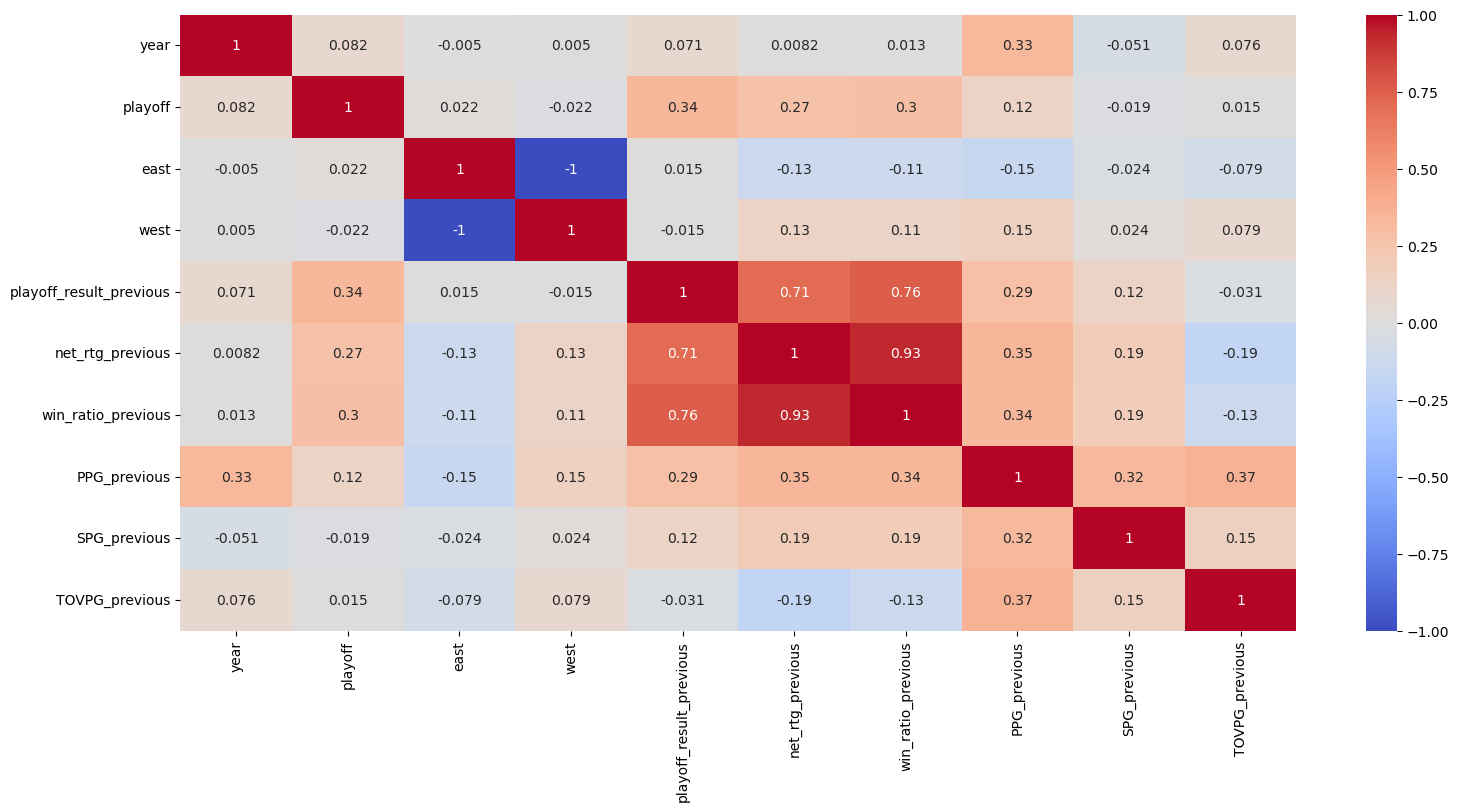

In [ ]:
teams = teams[['year', 'tmID','playoff','east','west','playoff_result_previous','net_rtg_previous','win_ratio_previous', 'PPG_previous', 'SPG_previous', 'TOVPG_previous']]

plt.figure(figsize=(18,8))
correlation = teams.corr()
sb.heatmap(correlation,annot=True,cmap='coolwarm')

In [ ]:
teams.dropna(inplace=True)

# select only a few columns
new_df = teams[['year','playoff','east','west', 'playoff_result_previous','net_rtg_previous','win_ratio_previous', 'PPG_previous', 'SPG_previous', 'TOVPG_previous']]

new_df

C:\Users\sofia\AppData\Local\Temp\ipykernel_18712\1139053813.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  teams.dropna(inplace=True)


,year,playoff,east,west,playoff_result_previous,net_rtg_previous,win_ratio_previous,PPG_previous,SPG_previous,TOVPG_previous
0,10,1,1,0,0,-12.7,0.12,6.45,0.84,1.41
1,2,1,1,0,0,-10.7,0.25,6.45,0.65,1.42
2,3,1,1,0,3,2.2,0.56,5.75,0.59,1.42
3,4,1,1,0,1,5.1,0.56,5.69,0.67,0.96
4,5,0,1,0,1,1.0,0.53,6.22,0.78,1.31
...,...,...,...,...,...,...,...,...,...,...
117,6,0,1,0,1,-2.4,0.50,6.70,0.72,1.24
118,7,1,1,0,0,-1.9,0.47,5.62,0.72,1.10
119,8,0,1,0,1,3.4,0.53,7.67,0.87,1.44
120,9,0,1,0,0,-2.1,0.47,6.31,0.79,1.27


# Testing models

In [ ]:
def showResults(y_test, predictions, model,collumns,save):
    # Calculate and print the confusion matrix
    cm = confusion_matrix(y_test, predictions)

    filename = model

    # Plot the confusion matrix
    plt.figure(figsize=(5, 5))
    sb.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Confusion matrix')
    plt.ylabel('Actual label')
    plt.xlabel('Predicted label')
    plt.show()

    # Print the classification report
    report = classification_report(y_test, predictions)

    print("Classification Report:\n", report)

In [ ]:
# drop the tmID, year, made_playoffs column
X = new_df.drop(['year', 'playoff'], axis=1).values
y = new_df['playoff']

# Get the column names
column_names = new_df.drop(['year', 'playoff'], axis=1).columns.tolist()

# Time-based split
train_end_year = 8
test_start_year = 9

train_mask = new_df['year'] <= train_end_year
test_mask = new_df['year'] >= test_start_year

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]

save_logs = False

Random Forest

Accuracy of the Random Forest model: 0.717948717948718


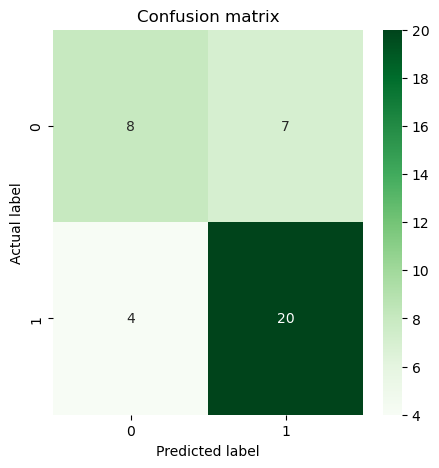

Classification Report:
               precision    recall  f1-score   support

           0       0.67      0.53      0.59        15
           1       0.74      0.83      0.78        24

    accuracy                           0.72        39
   macro avg       0.70      0.68      0.69        39
weighted avg       0.71      0.72      0.71        39



In [ ]:
# Train the model
model = RandomForestClassifier(n_estimators=200,random_state=42)
model.fit(X_train, y_train)

# Make predictions
predictions_rm = model.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_rm)
print(f"Accuracy of the Random Forest model: {accuracy}")

showResults(y_test, predictions_rm,"random_forest",column_names,save_logs)

k-Nearest Neighbors (k-NN)

Accuracy of the k-NN model: 0.5128205128205128


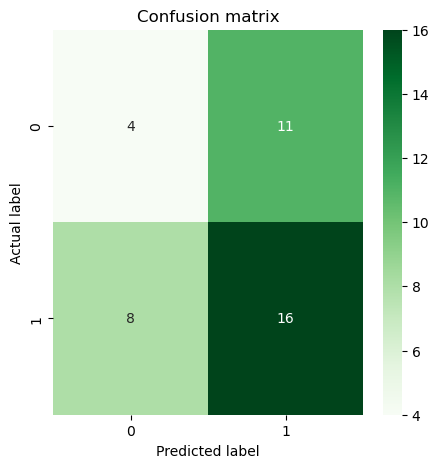

Classification Report:
               precision    recall  f1-score   support

           0       0.33      0.27      0.30        15
           1       0.59      0.67      0.63        24

    accuracy                           0.51        39
   macro avg       0.46      0.47      0.46        39
weighted avg       0.49      0.51      0.50        39



In [ ]:
# Train the model
model_knn = KNeighborsClassifier(n_neighbors=5)  # the desired number of neighbors (k)
model_knn.fit(X_train, y_train)

# Make predictions
predictions_knn = model_knn.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_knn)
print(f"Accuracy of the k-NN model: {accuracy}")

showResults(y_test, predictions_knn, "knn", column_names, save_logs)

Naive Bayes

Accuracy of the Naive Bayes model: 0.6410256410256411


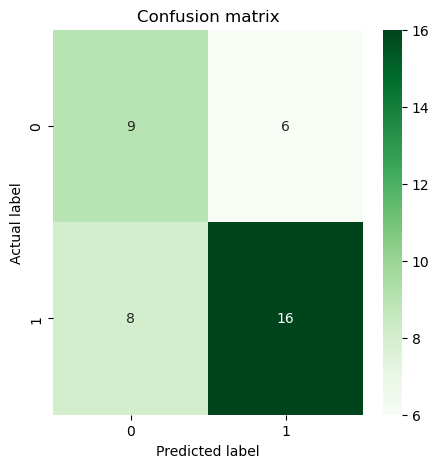

Classification Report:
               precision    recall  f1-score   support

           0       0.53      0.60      0.56        15
           1       0.73      0.67      0.70        24

    accuracy                           0.64        39
   macro avg       0.63      0.63      0.63        39
weighted avg       0.65      0.64      0.64        39



In [ ]:
# Train the model
model_nb = GaussianNB() 
model_nb.fit(X_train, y_train)

# Make predictions
predictions_nb = model_nb.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_nb)
print(f"Accuracy of the Naive Bayes model: {accuracy}")

showResults(y_test, predictions_nb, "naive_bayes", column_names, save_logs)

Multi-Layer Perceptron

Accuracy of the MLP model: 0.5897435897435898


c:\Users\sofia\anaconda\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:684: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


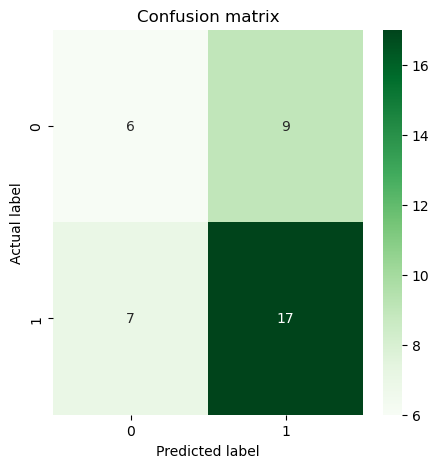

Classification Report:
               precision    recall  f1-score   support

           0       0.46      0.40      0.43        15
           1       0.65      0.71      0.68        24

    accuracy                           0.59        39
   macro avg       0.56      0.55      0.55        39
weighted avg       0.58      0.59      0.58        39



In [ ]:
# Train the model
model_mlp = MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=42)
model_mlp.fit(X_train, y_train)

# Make predictions
predictions_mlp = model_mlp.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_mlp)
print(f"Accuracy of the MLP model: {accuracy}")

showResults(y_test, predictions_mlp, "mlp", column_names, save_logs)

Decision Tree

Accuracy of the Decision Tree model: 0.6666666666666666


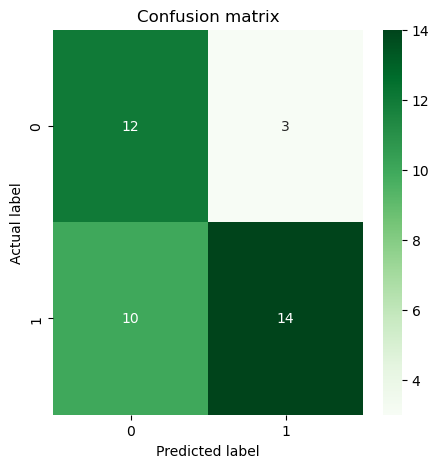

Classification Report:
               precision    recall  f1-score   support

           0       0.55      0.80      0.65        15
           1       0.82      0.58      0.68        24

    accuracy                           0.67        39
   macro avg       0.68      0.69      0.67        39
weighted avg       0.72      0.67      0.67        39



In [ ]:
# Train the model
model_dt = DecisionTreeClassifier(random_state=42)  
model_dt.fit(X_train, y_train)

# Make predictions
predictions_dt = model_dt.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_dt)
print(f"Accuracy of the Decision Tree model: {accuracy}")

showResults(y_test, predictions_dt, "decision_tree", column_names, save_logs)

Logistic Regression

Accuracy of the Logistic Regression model: 0.6410256410256411


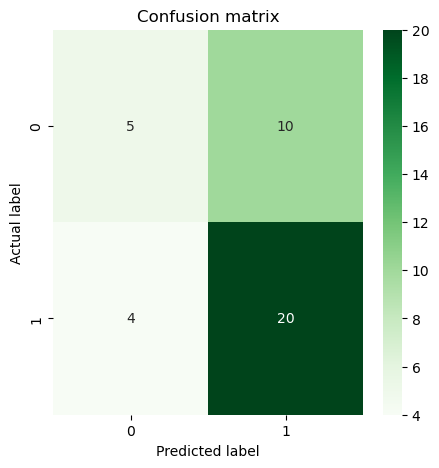

Classification Report:
               precision    recall  f1-score   support

           0       0.56      0.33      0.42        15
           1       0.67      0.83      0.74        24

    accuracy                           0.64        39
   macro avg       0.61      0.58      0.58        39
weighted avg       0.62      0.64      0.62        39



In [ ]:
# Train the model
model_lr = LogisticRegression(random_state=42)
model_lr.fit(X_train, y_train)

# Make predictions
predictions_lr = model_lr.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_lr)
print(f"Accuracy of the Logistic Regression model: {accuracy}")

showResults(y_test, predictions_lr, "logistic_regression", column_names, save_logs)

Gradient Boosting Classifier

Accuracy of the Gradient Boosting model: 0.6153846153846154


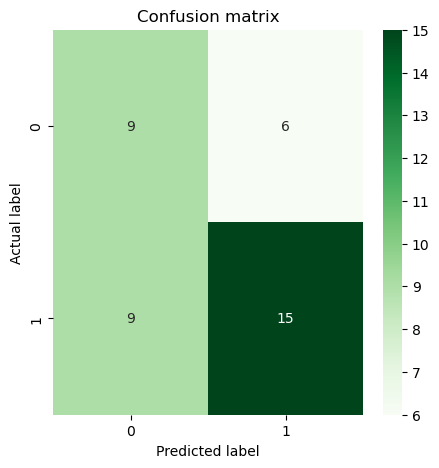

Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.60      0.55        15
           1       0.71      0.62      0.67        24

    accuracy                           0.62        39
   macro avg       0.61      0.61      0.61        39
weighted avg       0.63      0.62      0.62        39



In [ ]:
from sklearn.ensemble import GradientBoostingClassifier  

# Train the model
model_gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
model_gb.fit(X_train, y_train)

# Make predictions
predictions_gb = model_gb.predict(X_test)

# Model performance
accuracy = accuracy_score(y_test, predictions_gb)
print(f"Accuracy of the Gradient Boosting model: {accuracy}")

showResults(y_test, predictions_gb, "gradient_boosting", column_names, save_logs)

Support Vector Machine

Accuracy of the SVM model: 0.6153846153846154


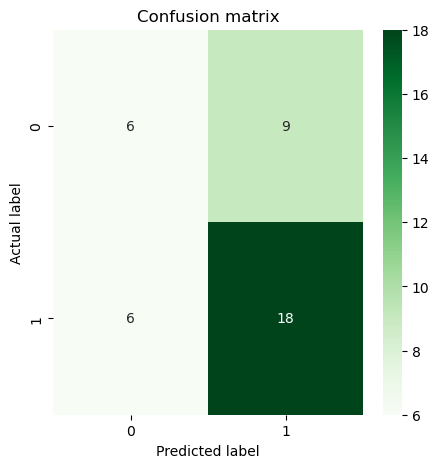

Classification Report:
               precision    recall  f1-score   support

           0       0.50      0.40      0.44        15
           1       0.67      0.75      0.71        24

    accuracy                           0.62        39
   macro avg       0.58      0.57      0.58        39
weighted avg       0.60      0.62      0.61        39



In [ ]:
from sklearn.svm import SVC 

# Train the model
model_svm = SVC(random_state=42)
model_svm.fit(X_train, y_train)

# Make predictions
predictions_svm = model_svm.predict(X_test)

# Model performance
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, predictions_svm)
print(f"Accuracy of the SVM model: {accuracy}")

showResults(y_test, predictions_svm, "svm", column_names, save_logs)